In [1]:
import pandas as pd

In [2]:
churn= pd.read_excel(r"C:\Users\SHAIKH MUSTAFA\Desktop\Fazila\Churn project\Telco-Customer-Churn.csv.xlsx")

In [3]:
churn.shape

(7043, 21)

In [4]:
churn.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [5]:
churn.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [6]:
churn.duplicated().sum()

np.int64(0)

In [7]:
churn["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [8]:
churn.dtypes

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

In [9]:
churn["TotalCharges"].head(10)

0      29.85
1     1889.5
2     108.15
3    1840.75
4     151.65
5      820.5
6     1949.4
7      301.9
8    3046.05
9    3487.95
Name: TotalCharges, dtype: object

In [10]:
churn["TotalCharges"].dtype

dtype('O')

In [11]:
churn["TotalCharges"].isnull().sum()

np.int64(0)

In [12]:
pd.to_numeric(churn["TotalCharges"], errors="coerce").head(10)

0      29.85
1    1889.50
2     108.15
3    1840.75
4     151.65
5     820.50
6    1949.40
7     301.90
8    3046.05
9    3487.95
Name: TotalCharges, dtype: float64

In [13]:
churn["TotalCharges"].head(10).map(repr)

0      29.85
1     1889.5
2     108.15
3    1840.75
4     151.65
5      820.5
6     1949.4
7      301.9
8    3046.05
9    3487.95
Name: TotalCharges, dtype: object

In [14]:
churn["TotalCharges"].value_counts(dropna=False).head(10)

TotalCharges
         11
20.2     11
19.75     9
20.05     8
19.9      8
19.65     8
45.3      7
19.55     7
20.15     6
20.25     6
Name: count, dtype: int64

In [15]:
churn["TotalCharges"] = pd.to_numeric(churn["TotalCharges"], errors="coerce")

In [16]:
churn["TotalCharges"].dtype

dtype('float64')

In [17]:
churn["TotalCharges"].isnull().sum()

np.int64(11)

In [18]:
churn[churn["TotalCharges"].isnull()][
    ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]
]

,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,NaN,No
753,0,20.25,NaN,No
936,0,80.85,NaN,No
1082,0,25.75,NaN,No
1340,0,56.05,NaN,No
3331,0,19.85,NaN,No
3826,0,25.35,NaN,No
4380,0,20.00,NaN,No
5218,0,19.70,NaN,No
6670,0,73.35,NaN,No


In [19]:
missing_records = churn[churn["TotalCharges"].isnull()]

print(missing_records[["tenure", "MonthlyCharges", "TotalCharges", "Churn"]].to_string())

      tenure  MonthlyCharges  TotalCharges Churn
488        0           52.55           NaN    No
753        0           20.25           NaN    No
936        0           80.85           NaN    No
1082       0           25.75           NaN    No
1340       0           56.05           NaN    No
3331       0           19.85           NaN    No
3826       0           25.35           NaN    No
4380       0           20.00           NaN    No
5218       0           19.70           NaN    No
6670       0           73.35           NaN    No
6754       0           61.90           NaN    No


In [20]:
missing_records["tenure"].value_counts(dropna=False)

tenure
0    11
Name: count, dtype: int64

In [21]:
churn["TotalCharges"] = churn["TotalCharges"].fillna(0)

In [22]:
churn["TotalCharges"].isnull().sum()

np.int64(0)

In [23]:
churn["Contract"].value_counts()

Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

In [24]:
churn["PaymentMethod"].value_counts()

PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64

In [25]:
churn["InternetService"].value_counts()

InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

In [26]:
churn.loc[churn["TotalCharges"].isnull(),["tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

,tenure,MonthlyCharges,TotalCharges,Churn


In [27]:
churn.loc[churn["TotalCharges"].isnull(), "tenure"].value_counts()

Series([], Name: count, dtype: int64)

In [28]:
churn.loc[churn["TotalCharges"].isnull(),["tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

,tenure,MonthlyCharges,TotalCharges,Churn


In [29]:
churn.loc[churn["TotalCharges"].isnull(), "tenure"].value_counts()

Series([], Name: count, dtype: int64)

In [30]:
churn["TotalCharges"].head(10)

0      29.85
1    1889.50
2     108.15
3    1840.75
4     151.65
5     820.50
6    1949.40
7     301.90
8    3046.05
9    3487.95
Name: TotalCharges, dtype: float64

In [31]:
churn.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [32]:
churn.duplicated().sum()

np.int64(0)

In [33]:
churn["customerID"].duplicated().sum()

np.int64(0)

In [34]:
churn.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [35]:
churn["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [36]:
churn["Churn"].value_counts(normalize=True) * 100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

In [37]:
# Overall Customer Churn 

total_customers = churn["customerID"].nunique()

churned_customers = (churn["Churn"] == "Yes").sum()

churn_rate = (churned_customers / total_customers) * 100

print("Total Customers:", total_customers)
print("Churned Customers:", churned_customers)
print("Churn Rate:", round(churn_rate, 2), "%")

Total Customers: 7043
Churned Customers: 1869
Churn Rate: 26.54 %


In [38]:
# Analyze churn by contract type

churn["Contract"].value_counts()

Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

In [39]:
pd.crosstab(
    churn["Contract"],
    churn["Churn"],
    normalize="index"
) * 100

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


In [40]:
# Key finding :Month-to-month customers have the highest churn rate

In [41]:
# Churn by tenure

churn.groupby("Churn")["tenure"].mean()

Churn
No     37.569965
Yes    17.979133
Name: tenure, dtype: float64

In [42]:
# Key finding :Customers with shorter relationships appear more likely to leave.

In [43]:
# Churn by monthly charges

churn.groupby("Churn")["MonthlyCharges"].mean()

Churn
No     61.265124
Yes    74.441332
Name: MonthlyCharges, dtype: float64

In [44]:
# Key finding :Customers with higher average monthly charges were more likely to churn.

In [45]:
# Churn by payment method

pd.crosstab(
    churn["PaymentMethod"],
    churn["Churn"],
    normalize="index"
) * 100

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.290155,16.709845
Credit card (automatic),84.756899,15.243101
Electronic check,54.714588,45.285412
Mailed check,80.893300,19.106700


In [46]:
# Key finding :Customers using electronic checks have substantially higher churn.

In [47]:
# Churn by internet service

pd.crosstab(
    churn["InternetService"],
    churn["Churn"],
    normalize="index"
) * 100

Churn,No,Yes
InternetService,,
DSL,81.040892,18.959108
Fiber optic,58.107235,41.892765
No,92.595020,7.404980


In [48]:
 # Key finding: Fiber optic customers are more likely to leave than customers in the other categories.

In [49]:
# Churn by gender

pd.crosstab(
    churn["gender"],
    churn["Churn"],
    normalize="index"
) * 100

Churn,No,Yes
gender,,
Female,73.079128,26.920872
Male,73.839662,26.160338


In [50]:
# Churn by Senior Citizen

pd.crosstab(
    churn["SeniorCitizen"],
    churn["Churn"],
    normalize="index"
) * 100

Churn,No,Yes
SeniorCitizen,,
0,76.393832,23.606168
1,58.318739,41.681261


In [51]:
# Churn by tech support

pd.crosstab(
    churn["TechSupport"],
    churn["Churn"],
    normalize="index"
) * 100

Churn,No,Yes
TechSupport,,
No,58.364526,41.635474
No internet service,92.595020,7.404980
Yes,84.833659,15.166341


In [52]:
# Churn by online security

pd.crosstab(
    churn["OnlineSecurity"],
    churn["Churn"],
    normalize="index"
) * 100

Churn,No,Yes
OnlineSecurity,,
No,58.233276,41.766724
No internet service,92.595020,7.404980
Yes,85.388806,14.611194


In [53]:
# Churn by online backup

pd.crosstab(
    churn["OnlineBackup"],
    churn["Churn"],
    normalize="index"
) * 100


Churn,No,Yes
OnlineBackup,,
No,60.071244,39.928756
No internet service,92.595020,7.404980
Yes,78.468506,21.531494


In [54]:
churn["TenureGroup"] = pd.cut(
    churn["tenure"],
    bins=[-1, 12, 24, 48, 60, 72],
    labels=["0-12 months", "13-24 months", "25-48 months",
            "49-60 months", "61-72 months"]
)

In [55]:
pd.crosstab(
    [churn["Contract"], churn["TenureGroup"]],
    churn["Churn"],
    normalize="index"
) * 100

Churn                                No        Yes
Contract       TenureGroup                        
Month-to-month 0-12 months    48.645938  51.354062
               13-24 months   62.279512  37.720488
               25-48 months   67.082294  32.917706
               49-60 months   72.222222  27.777778
               61-72 months   77.777778  22.222222
One year       0-12 months    89.516129  10.483871
               13-24 months   91.878173   8.121827
               25-48 months   89.382239  10.617761
               49-60 months   86.292835  13.707165
               61-72 months   87.859425  12.140575
Two year       0-12 months   100.000000   0.000000
               13-24 months  100.000000   0.000000
               25-48 months   97.810219   2.189781
               49-60 months   96.028881   3.971119
               61-72 months   96.855984   3.144016

In [56]:
pd.crosstab(
    [churn["Contract"], churn["TenureGroup"]],
    churn["Churn"]
)

Churn                         No   Yes
Contract       TenureGroup            
Month-to-month 0-12 months   970  1024
               13-24 months  459   278
               25-48 months  538   264
               49-60 months  169    65
               61-72 months   84    24
One year       0-12 months   111    13
               13-24 months  181    16
               25-48 months  463    55
               49-60 months  277    44
               61-72 months  275    38
Two year       0-12 months    68     0
               13-24 months   90     0
               25-48 months  268     6
               49-60 months  266    11
               61-72 months  955    31

In [57]:
import matplotlib.pyplot as plt

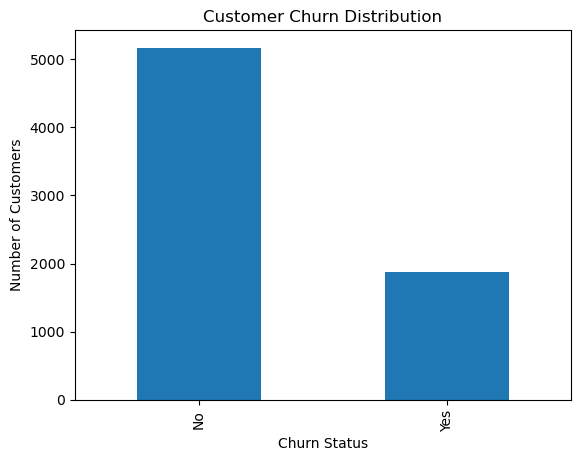

In [61]:
churn["Churn"].value_counts().plot(kind="bar")

# Chart 1: Overall customer churn

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")
plt.show()

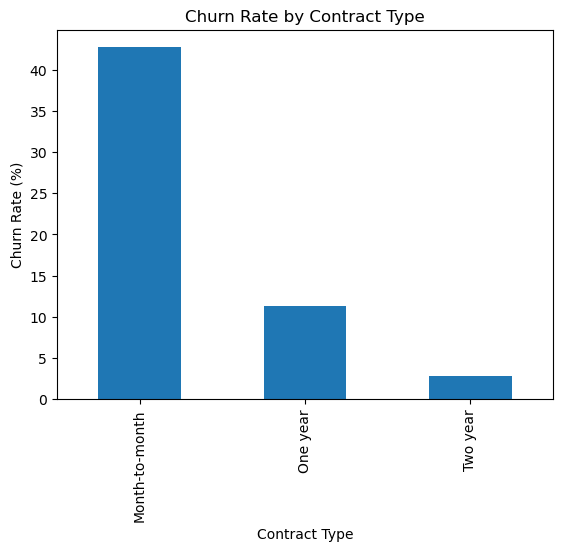

In [62]:
# Chart 2: Churn Rate by Contract Type

churn_rate = pd.crosstab(
    churn["Contract"],
    churn["Churn"],
    normalize="index"
) * 100

churn_rate["Yes"].plot(kind="bar")

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")

plt.show()

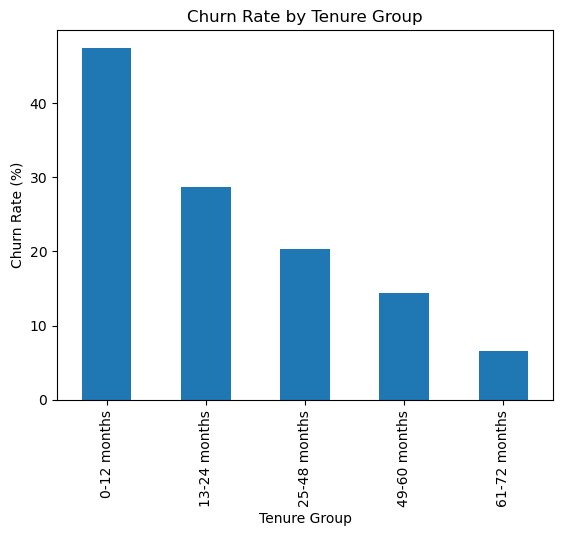

In [63]:
# Chart 3: Churn Rate by Tenure Group

tenure_churn = pd.crosstab(
    churn["TenureGroup"],
    churn["Churn"],
    normalize="index"
) * 100

tenure_churn["Yes"].plot(kind="bar")

plt.title("Churn Rate by Tenure Group")
plt.xlabel("Tenure Group")
plt.ylabel("Churn Rate (%)")

plt.show()

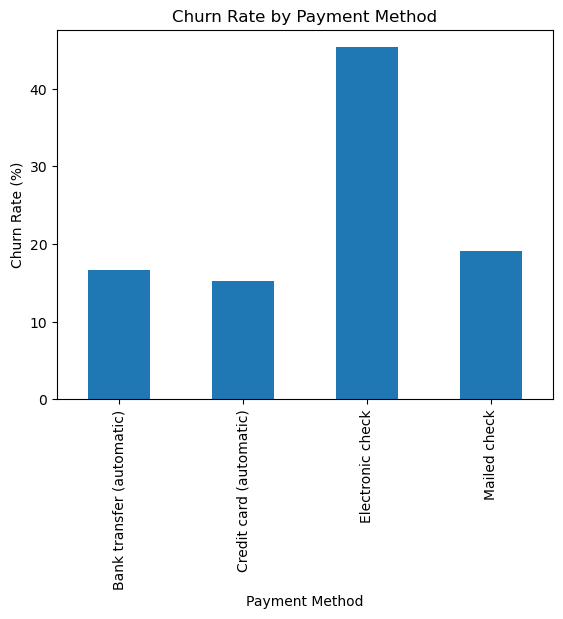

In [64]:
# Chart 4: Churn Rate by Payment Method

payment_churn = pd.crosstab(
    churn["PaymentMethod"],
    churn["Churn"],
    normalize="index"
) * 100

payment_churn["Yes"].plot(kind="bar")

plt.title("Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")

plt.show()

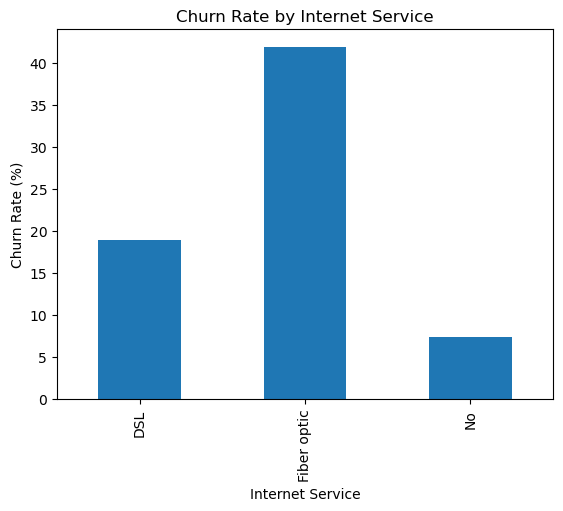

In [65]:
# Chart 5: Churn Rate by Internet Service

internet_churn = pd.crosstab(
    churn["InternetService"],
    churn["Churn"],
    normalize="index"
) * 100

internet_churn["Yes"].plot(kind="bar")

plt.title("Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate (%)")

plt.show()

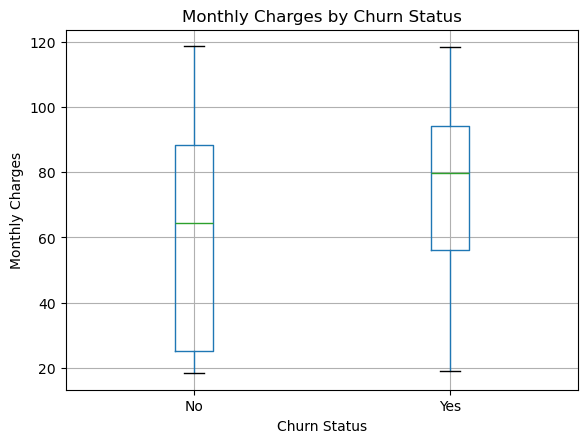

In [66]:
# Chart 6: Monthly Charges by Churn Status

churn.boxplot(
    column="MonthlyCharges",
    by="Churn"
)

plt.title("Monthly Charges by Churn Status")
plt.suptitle("")
plt.xlabel("Churn Status")
plt.ylabel("Monthly Charges")

plt.show()

In [67]:
churn.to_excel(r"C:\Users\SHAIKH MUSTAFA\Desktop\Fazila\Churn project\Telco-Customer-Churn.csv.xlsx")

In [68]:
import os

os.getcwd()

'C:\\Users\\SHAIKH MUSTAFA'